In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import glob
import os
import pandas as pd, calendar

files = sorted(glob.glob(r"C:\Users\PatrickOrenstein\OneDrive - ZeroEx GmbH\ZeroEx - ZX_Scientific\03_CDR_Calculation\03_EW_Model\02_Weather_Statistics\Brazil_kaggle_weather_data\*_data.csv"))
station_names = ['Caiapoia', 'Edeia', 'Jatai', 'Parauna', 'Rio Verde']

months = np.arange(1, 13)  # Month numbers for indexing
month_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
colors = ['#E6FF2A', '#38F295', '#177F75', '#13A1D3', '#333333']
colors = ['#D9ED21', '#38F295', '#DD7D14', '#158BBA', '#333333']


In [2]:
df_rio_verde = pd.read_csv(r"C:\Users\PatrickOrenstein\OneDrive - ZeroEx GmbH\ZeroEx - ZX_Scientific\03_CDR_Calculation\03_EW_Model\02_Weather_Statistics\Brazil_kaggle_weather_data\rio_verde_station_data.csv")
df_rio_verde['datetime'] = pd.to_datetime(df_rio_verde['date'].astype(str) + ' ' + df_rio_verde['hr'].astype(str))
df_rio_verde['month'] = df_rio_verde['datetime'].dt.month
df_rio_verde.columns

Index(['Unnamed: 0', 'date', 'hr', 'prcp', 'stp', 'smax', 'smin', 'gbrd',
       'temp', 'dewp', 'tmax', 'tmin', 'dmax', 'dmin', 'hmax', 'hmin', 'hmdy',
       'wdct', 'gust', 'wdsp', 'region', 'prov', 'wsnm', 'inme', 'lat', 'lon',
       'elvt', 'datetime', 'month'],
      dtype='object')

In [ ]:
df = df_rio_verde.copy()

df_new = df_rio_verde.set_index('datetime').resample('D').agg(
    total_rain_mm=('prcp', 'sum'),
    min_rain_mm=('prcp', 'min'),
    max_rain_mm=('prcp', 'max'),
    std_rain_mm=('prcp', 'std'),
    month = ('month', 'mean'),
    date = ('date', 'first'),
    temp = ('temp', 'mean'),
    tmax = ('tmax', 'max'),
    tmin = ('tmin','min'),
    hmdy = ('hmdy', 'mean'),
    wdsp = ('wdsp', 'mean'),
    max_gust = ('gust', 'max'),
    rain=('prcp', lambda x: (x > 0).sum()),
)


df_new['daily_temp_range'] = np.abs(df_new['tmax'] - df_new['tmin'])

print(df_new['temp'].mean())
print(df_new['temp'].max() - df_new['temp'].min())
print(df_new['daily_temp_range'].mean())


# ---- fixed aggregation ----
monthly_summary = df_new.groupby('month').agg(
    total_rain_mm=('total_rain_mm', 'sum'),
    
    rain_days=('total_rain_mm', lambda x: (x > 0.1).sum()),
    total_days=('total_rain_mm', 'count'),

    mean_daily_temp=('temp', 'mean'),
    max_daily_temp=('tmax', 'max'),
    min_daily_temp=('tmin', 'min'),
    std_daily_temp=('temp', 'std')
)


# Calculate probability of rain
monthly_summary['rain_probability'] = monthly_summary['rain_days'] / monthly_summary['total_days']
monthly_summary['conditional_mean_rain_mm'] = monthly_summary['total_rain_mm'] / monthly_summary['rain_days'] # conditional mean
monthly_summary['unconditional_mean_rain_mm'] = monthly_summary['total_rain_mm'] / monthly_summary['total_days'] # unconditional mean


n_years = np.round(monthly_summary.total_days/30) # trying to account for missing months, I think...

monthly_summary['mean_monthly_rain_mm'] = monthly_summary['total_rain_mm'] / n_years



25.657211795048063
22.82371794871795
11.807226778984703


In [ ]:
import smew

################## Rio Verde weather station conditions - added 14.08.2025
# lamda/alfa/temp_* derived directly from the raw station CSV via
# smew.stoch_lambda_alpha (previously alfa was hand-computed here and was
# actually total monthly rainfall, not mean rain depth per rain event --
# ~1-18x too large depending on month; see smew/stoch_lambda_alpha.py)
stoch_params = smew.stoch_lambda_alpha("Field_data/rio_verde_station_data.csv")

temp_av = stoch_params['temp_av']           # [°C] yearly average
temp_ampl_yr = stoch_params['temp_ampl_yr']  # [°C] yearly amplitude (range/2)
temp_ampl_d = stoch_params['temp_ampl_d']    # [°C] daily amplitude (range/2)

lamda = stoch_params['lamda']  # [d^-1]: average rain frequency, Jan..Dec
alfa = stoch_params['alfa']    # [m]: average rain depth per rain event, Jan..Dec

days_per_month = np.array([31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31])
R_tot = np.sum(lamda * alfa * days_per_month)  # [m/yr], implied by lamda/alfa -- cross-check against observed annual rainfall
#####################################


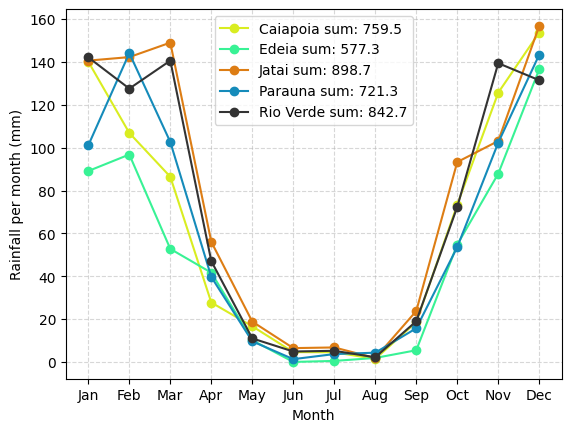

In [5]:

plt.figure()

for i, (file, name, color) in enumerate(zip(files, station_names, colors)):

    df = pd.read_csv(file)

    df['datetime'] = pd.to_datetime(df['date'].astype(str) + ' ' + df['hr'].astype(str))

    # 2) monthly sums per year-month
    monthly_sums = df.groupby(df['datetime'].dt.to_period('M'))['prcp'].sum()

    # 3) mean of those monthly sums for each calendar month across years
    moy_mean = (
        monthly_sums
        .groupby(monthly_sums.index.month)  # 1..12
        .mean()
        .rename_axis('month')
    )

    # (optional) nice month labels
    moy_mean.index = [calendar.month_abbr[i] for i in moy_mean.index]

    plt.plot(months, moy_mean.values, marker='o', label=name + ' sum: ' + str(np.sum(moy_mean.values))[:5], color=color)
    
plt.ylabel('Rainfall per month (mm)')
plt.xlabel('Month')
plt.legend()

plt.xticks(months, month_labels)

plt.grid(True, linestyle='--', alpha=0.5)

plt.savefig(r"C:\Users\PatrickOrenstein\OneDrive - ZeroEx GmbH\ZeroEx - ZX_Scientific\03_CDR_Calculation\03_EW_Model\02_Weather_Statistics\Brazil_kaggle_weather_data\monthly_rainfall_lines.pdf")

plt.show()




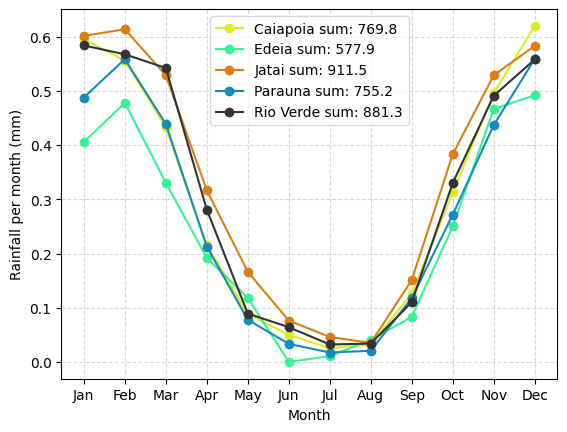

In [6]:


plt.figure()

for i, (file, name, color) in enumerate(zip(files, station_names, colors)):

    df = pd.read_csv(file)

    df['datetime'] = pd.to_datetime(df['date'].astype(str) + ' ' + df['hr'].astype(str))
    df['month'] = df['datetime'].dt.month


    df_new = df.set_index('datetime').resample('D').agg(
        total_rain_mm=('prcp', 'sum'),
        min_rain_mm=('prcp', 'min'),
        max_rain_mm=('prcp', 'max'),
        std_rain_mm=('prcp', 'std'),
        month = ('month', 'mean'),
        date = ('date', 'first'),
        temp = ('temp', 'mean'),
        tmax = ('tmax', 'max'),
        tmin = ('tmin','min'),
        hmdy = ('hmdy', 'mean'),
        wdsp = ('wdsp', 'mean'),
        max_gust = ('gust', 'max'),
        rain=('prcp', lambda x: (x > 0).sum()),
    )


    df_new['daily_temp_range'] = np.abs(df_new['tmax'] - df_new['tmin'])



    # ---- fixed aggregation ----
    monthly_summary = df_new.groupby('month').agg(
        total_rain_mm=('total_rain_mm', 'sum'),
        
        rain_days=('total_rain_mm', lambda x: (x > 0.1).sum()),
        total_days=('total_rain_mm', 'count'),

        mean_daily_temp=('temp', 'mean'),
        max_daily_temp=('tmax', 'max'),
        min_daily_temp=('tmin', 'min'),
        std_daily_temp=('temp', 'std')
    )



    # Calculate probability of rain
    monthly_summary['rain_probability'] = monthly_summary['rain_days'] / monthly_summary['total_days']
    monthly_summary['conditional_mean_rain_mm'] = monthly_summary['total_rain_mm'] / monthly_summary['rain_days'] # conditional mean
    monthly_summary['unconditional_mean_rain_mm'] = monthly_summary['total_rain_mm'] / monthly_summary['total_days'] # unconditional mean


    n_years = np.round(monthly_summary.total_days/30) # trying to account for missing months, I think...

    monthly_summary['mean_monthly_rain_mm'] = monthly_summary['total_rain_mm'] / n_years




    plt.plot(months, monthly_summary['rain_probability'], marker='o', label=name + ' sum: ' + str(np.sum(monthly_summary['mean_monthly_rain_mm']))[:5], color=color)
    
plt.ylabel('Rainfall per month (mm)')
plt.xlabel('Month')
plt.legend()

plt.xticks(months, month_labels)

plt.grid(True, linestyle='--', alpha=0.5)

# plt.savefig(r"C:\Users\PatrickOrenstein\OneDrive - ZeroEx GmbH\ZeroEx - ZX_Scientific\03_CDR_Calculation\03_EW_Model\02_Weather_Statistics\Brazil_kaggle_weather_data\monthly_rainfall_lines.pdf")

plt.show()


In [8]:
df_new['wdsp'].mean()

2.327779333175391

In [11]:
df_new['max_gust'].mean()

9.11367767679007

In [10]:
df_new

,total_rain_mm,min_rain_mm,max_rain_mm,std_rain_mm,month,date,temp,tmax,tmin,hmdy,wdsp,max_gust,rain,daily_temp_range
datetime,,,,,,,,,,,,,,
2007-05-17,0.0,0.0,0.0,0.0,5.0,2007-05-17,28.880000,30.9,25.3,33.600000,2.100000,6.8,0,5.6
2007-05-18,0.0,0.0,0.0,0.0,5.0,2007-05-18,26.583333,30.8,17.3,42.333333,2.500000,7.6,0,13.5
2007-05-19,0.0,0.0,0.0,0.0,5.0,2007-05-19,26.416667,30.1,18.6,39.416667,1.850000,5.8,0,11.5
2007-05-20,0.0,0.0,0.0,0.0,5.0,2007-05-20,25.741667,29.9,16.1,43.666667,2.766667,7.3,0,13.8
2007-05-21,0.0,0.0,0.0,0.0,5.0,2007-05-21,26.508333,30.8,18.0,46.666667,2.675000,7.9,0,12.8
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2021-02-27,0.0,NaN,NaN,NaN,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN
2021-02-28,0.0,NaN,NaN,NaN,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN
2021-03-01,0.0,NaN,NaN,NaN,NaN,None,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN
